# Linear and Nonlinear Regression

Regression is the workhorse of engineering data analysis. Calibration curves, empirical material laws, characteristic maps of engines and process models are all regression models: they describe how a quantity of interest – the *response* – depends on one or more influencing quantities – the *inputs*, *factors* or *features*. A regression model can be used to **understand** a process (which factors matter, how strongly?) and to **predict** the response for new input values.

This chapter starts with the multiple linear regression model, its estimation by least squares and the statistical tools to interpret and check it. We then fit nonlinear models with physical meaning, which are common in engineering. An extension section shows how designed experiments make sure that the data actually contain the information we need.

::: {.scenario}
**Scenario: releasing a precast element**

A precast concrete plant wants to use a new, cheaper mix: 350 kg cement and 180 kg water per m³, 5 kg superplasticizer, no slag or fly ash. The elements require a compressive strength of 35 MPa before they may be loaded. No test specimens of the new mix exist yet, and the production manager asks: "Can we promise the customer 35 MPa after 28 days – and if not, when?"

**Your decision:** Approve the mix for the 28-day delivery promise – or name a later date?
:::

**Learning goals.** After this chapter you can

- fit and interpret multiple linear regression models with statsmodels,
- explain least squares, coefficient standard errors, R² and the difference between confidence and prediction intervals,
- check model assumptions with residual analysis and recognise collinearity,
- include transformations and interaction terms,
- fit nonlinear physical or empirical models with `scipy.optimize.curve_fit` and quantify parameter uncertainty,
- (extension) plan a full factorial experiment and estimate main effects and interactions.

**Datasets in this chapter**

- [Concrete Compressive Strength (UCI)](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength)

## The linear model

::: {.callout-note}
## Definition: Multiple linear regression
The response $y$ is modelled as a linear function of $p$ inputs plus a random error:
$$y_i = \beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip} + \varepsilon_i, \qquad \varepsilon_i \sim N(0, \sigma^2) \text{ independent}.$$
In matrix form, $y = X\beta + \varepsilon$, where the design matrix $X$ has a first column of ones for the intercept.
:::

"Linear" refers to the **parameters**, not to the inputs. Models like $y = \beta_0 + \beta_1 \ln x + \beta_2 x^2$ or $y = \beta_0 + \beta_1 x_1 x_2$ are linear models, because they are linear in $\beta$. This makes the linear model much more flexible than its name suggests.

### Estimation by least squares

The coefficients are chosen to minimise the sum of squared residuals $\sum_i (y_i - \hat y_i)^2$. Setting the derivatives to zero gives the **normal equations** and their solution:

::: {.callout-important}
## Least squares estimate
$$\hat\beta = (X^\top X)^{-1} X^\top y, \qquad \widehat{\text{Cov}}(\hat\beta) = \hat\sigma^2 (X^\top X)^{-1}, \qquad \hat\sigma^2 = \frac{1}{n - p - 1}\sum_i (y_i - \hat y_i)^2.$$
The square roots of the diagonal of $\widehat{\text{Cov}}(\hat\beta)$ are the **standard errors** of the coefficients.
:::

(Numerically, software never inverts $X^\top X$ explicitly but uses a QR or SVD decomposition – more stable, same result.)

### Interpreting the output

- **Coefficient $\hat\beta_j$:** expected change of $y$ when $x_j$ increases by one unit *and all other inputs stay constant*. The last part is crucial – and often unrealistic when inputs are correlated.
- **Standard error, t-value, p-value:** test of $H_0: \beta_j = 0$ given the other inputs in the model; the 95 % confidence interval is $\hat\beta_j \pm t_{0.975}\,\text{SE}(\hat\beta_j)$.
- **Coefficient of determination** $R^2 = 1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$: share of the variance of $y$ explained by the model. It never decreases when inputs are added; the **adjusted $R^2$** penalises additional inputs.

::: {.callout-warning}
## Pitfall: R² measures fit, not validity
A high $R^2$ does not mean that the model is correct, that it predicts well on new data or that the relationships are causal. Conversely, a low $R^2$ can be perfectly acceptable if the process is inherently noisy. Always look at the residuals – and, for prediction, at the error on test data (Chapter 6).
:::

### Model assumptions and residual analysis

The statistical statements (standard errors, p-values, intervals) rely on assumptions about the errors. The **residuals** $e_i = y_i - \hat y_i$ are our window to check them:

| Assumption | Check | Typical violation in engineering data |
| --- | --- | --- |
| Linearity (correct functional form) | residuals vs. fitted values and vs. each input: no pattern | saturation, threshold effects |
| Constant variance | spread of residuals constant | relative errors: spread grows with the response |
| Independence | residuals vs. time / order | time series, batches, repeated measurements on the same part |
| Normality | QQ plot of residuals | outliers, skewed responses |

::: {.callout-tip}
## Engineering practice: transformations
Many engineering relationships are multiplicative or saturating. A log transformation of the response or of an input often linearises the relationship and stabilises the variance at the same time. Physical knowledge tells you which transformation makes sense: for concrete, strength grows quickly at first and then levels off, which suggests $\ln(\text{age})$.
:::

### Collinearity

When inputs are strongly correlated, their individual effects cannot be separated well: the coefficients get large standard errors, can have implausible signs and change strongly when another input is added. The **variance inflation factor** $\text{VIF}_j = 1/(1 - R_j^2)$, where $R_j^2$ is the $R^2$ of regressing $x_j$ on all other inputs, quantifies this; values above about 5–10 indicate problematic collinearity. Collinearity does not harm predictions within the range of the data, but it ruins the interpretation of individual coefficients.

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm

sns.set_theme(style="whitegrid")

## Live coding: concrete strength

The dataset contains 1,030 laboratory tests of concrete. Each test is described by the amounts of seven mixture components in kg per m³ of concrete and the age of the specimen at testing (1 to 365 days); the response is the compressive strength in MPa. Concrete strength is a classic example of a highly nonlinear material property: it depends on the water/cement ratio, on supplementary materials such as blast furnace slag and fly ash, on the superplasticizer and on the curing time.

In [2]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo

concrete = fetch_ucirepo(id=165)
conc = concrete.data.features.copy()
conc.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                "coarse_agg", "fine_agg", "age"]          # kg/m³, age in days
conc["strength"] = concrete.data.targets.iloc[:, 0]        # MPa
conc.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.2,104.5,102.0,192.4,272.9,350.0,540.0
slag,1030.0,73.9,86.3,0.0,0.0,22.0,143.0,359.4
fly_ash,1030.0,54.2,64.0,0.0,0.0,0.0,118.3,200.1
water,1030.0,181.6,21.4,121.8,164.9,185.0,192.0,247.0
superplasticizer,1030.0,6.2,6.0,0.0,0.0,6.4,10.2,32.2
coarse_agg,1030.0,972.9,77.8,801.0,932.0,968.0,1029.4,1145.0
fine_agg,1030.0,773.6,80.2,594.0,731.0,779.5,824.0,992.6
age,1030.0,45.7,63.2,1.0,7.0,28.0,56.0,365.0
strength,1030.0,35.8,16.7,2.3,23.7,34.4,46.1,82.6


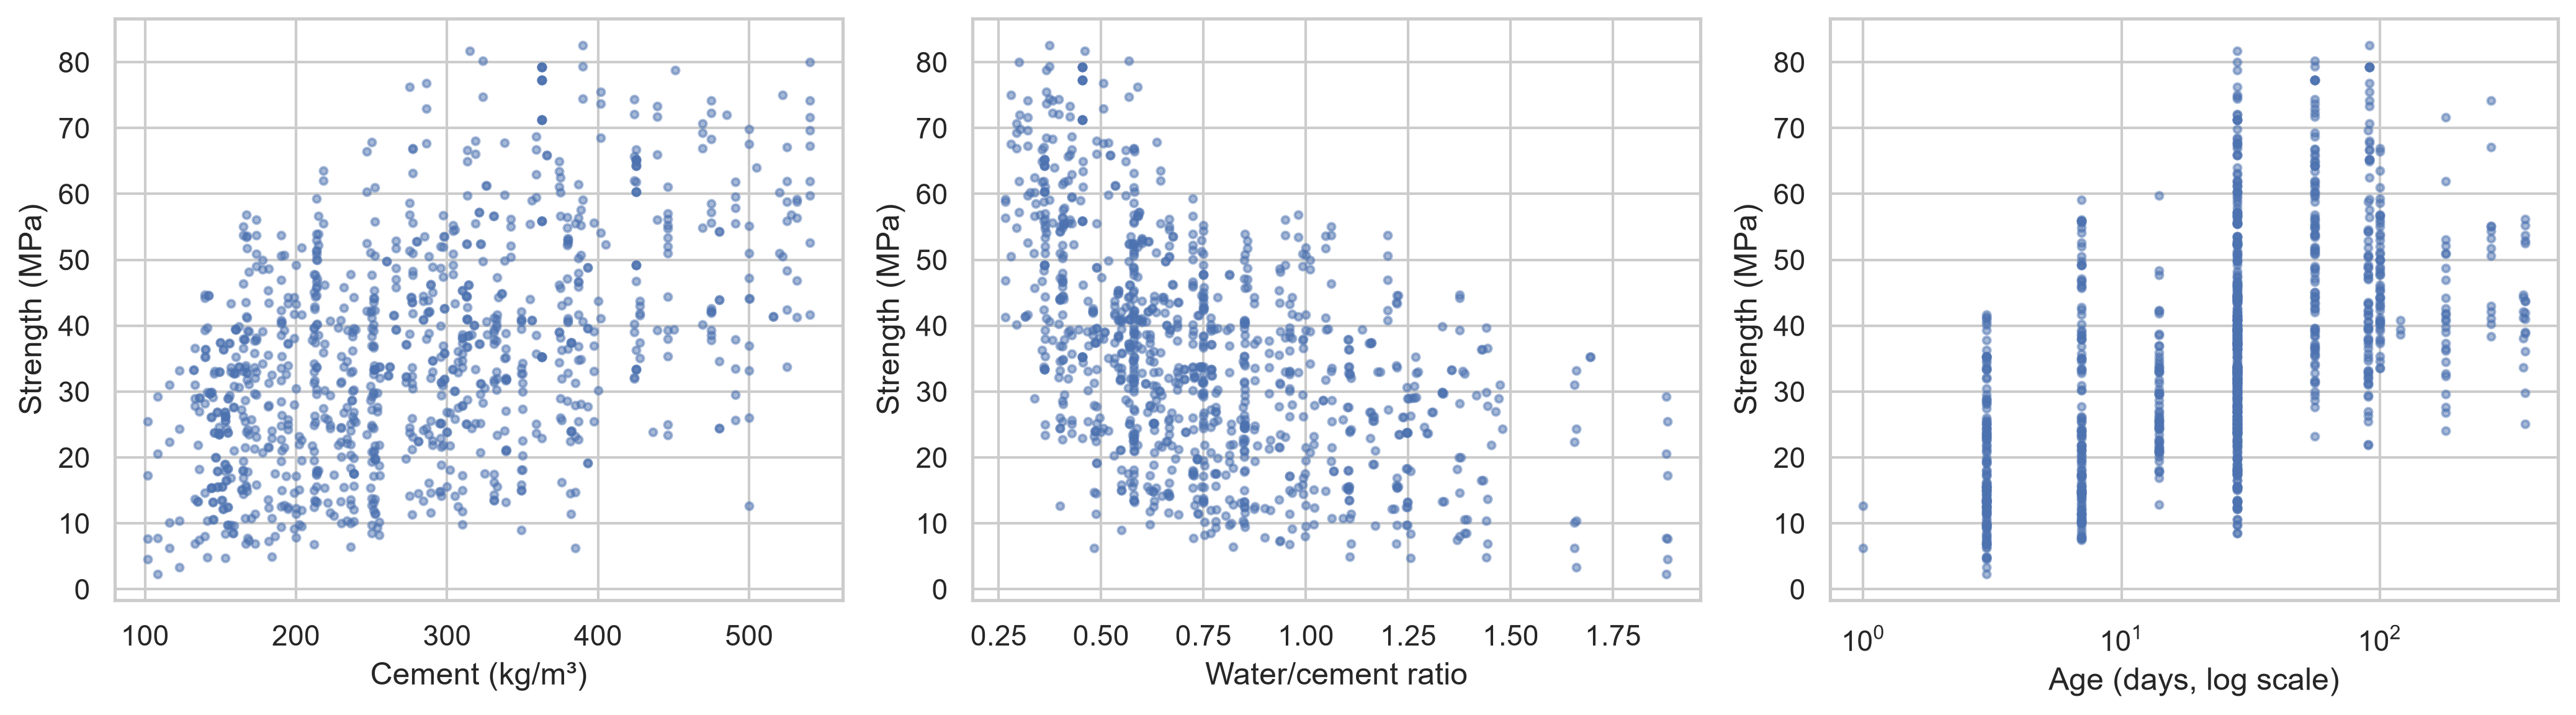

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(conc["cement"], conc["strength"], s=8, alpha=0.5)
axes[0].set(xlabel="Cement (kg/m³)", ylabel="Strength (MPa)")
axes[1].scatter(conc["water"] / conc["cement"], conc["strength"], s=8, alpha=0.5)
axes[1].set(xlabel="Water/cement ratio", ylabel="Strength (MPa)")
axes[2].scatter(conc["age"], conc["strength"], s=8, alpha=0.5)
axes[2].set(xscale="log", xlabel="Age (days, log scale)", ylabel="Strength (MPa)")
plt.tight_layout(); plt.show()

Strength increases with the cement content, decreases with the water/cement ratio (a classical rule in concrete technology, known as Abrams' law) and grows with age – roughly linearly in the *logarithm* of the age. We therefore enter age as $\ln(\text{age})$:

In [4]:
#| code-fold: false
model = smf.ols("strength ~ cement + slag + fly_ash + water + superplasticizer"
                " + coarse_agg + fine_agg + np.log(age)", data=conc).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               strength   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.817
Method:                 Least Squares   F-statistic:                     575.6
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:58:09   Log-Likelihood:                -3482.4
No. Observations:                1030   AIC:                             6983.
Df Residuals:                    1021   BIC:                             7027.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          -77.5334     18.331  

**Discussion.** Read the summary from top to bottom:

- **R² and adjusted R²** tell you how much of the variation in strength the model explains.
- **Coefficients:** each value is the change in MPa per additional kg/m³ of the component (or per unit of $\ln$ age), holding all other components constant. Cement, slag and fly ash act as binders and should have positive coefficients; water should have a negative one.
- **Holding constant is tricky here:** the components add up to roughly the volume of one cubic metre. If we add more cement, something else must be reduced. This built-in dependence causes collinearity, which explains why some aggregate coefficients can be small or have surprising signs.
- **Notes at the bottom:** statsmodels warns, for example, about a large condition number – a hint at collinearity or very differently scaled inputs.

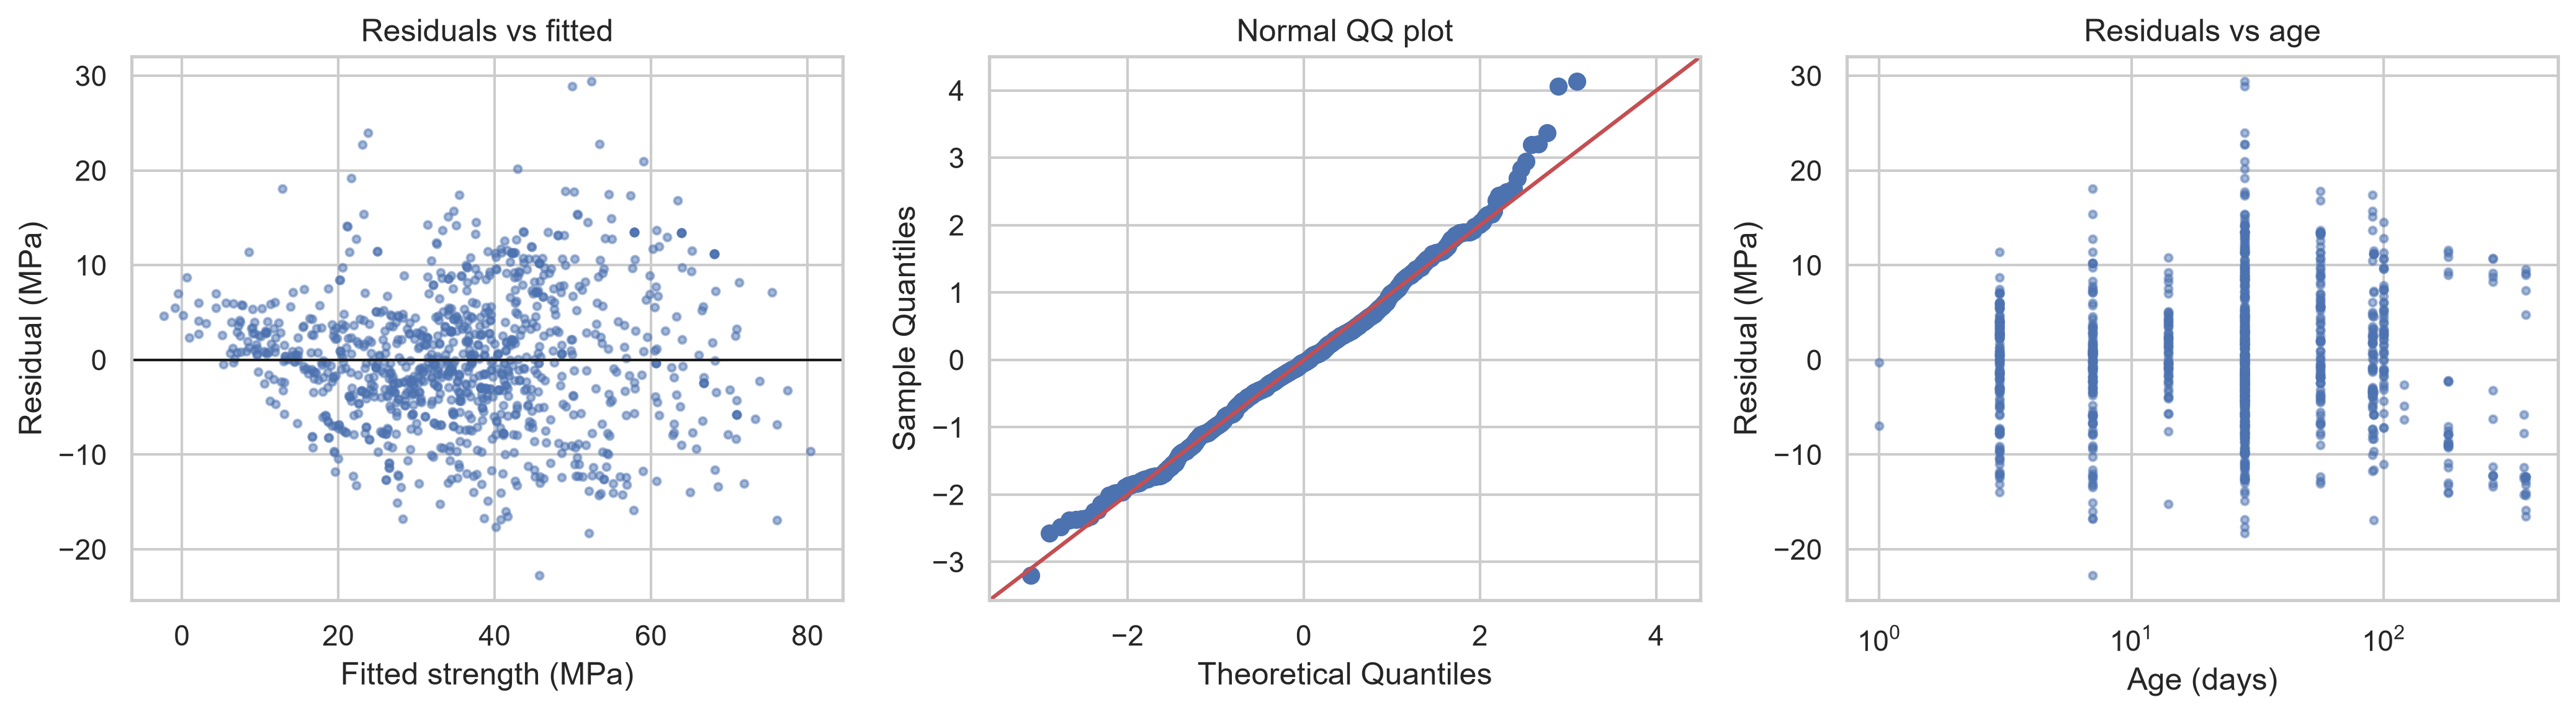

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(model.fittedvalues, model.resid, s=8, alpha=0.5)
axes[0].axhline(0, color="k", lw=1)
axes[0].set(xlabel="Fitted strength (MPa)", ylabel="Residual (MPa)", title="Residuals vs fitted")
sm.qqplot(model.resid, line="45", fit=True, ax=axes[1]); axes[1].set_title("Normal QQ plot")
axes[2].scatter(conc["age"], model.resid, s=8, alpha=0.5)
axes[2].set(xscale="log", xlabel="Age (days)", ylabel="Residual (MPa)", title="Residuals vs age")
plt.tight_layout(); plt.show()

**Discussion.** Look for patterns: a curved band in the residuals vs. fitted values indicates a missing nonlinearity; a funnel shape indicates non-constant variance; structure in the residuals vs. age shows that the $\ln$ transformation captures the age effect only approximately. Systematic patterns tell us that the linear model is an approximation – which is fine for interpretation of the main effects but limits its predictive accuracy. Flexible models in Chapters 6 and 8 will do better.

In [6]:
#| code-fold: false
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xv = sm.add_constant(conc[["cement", "slag", "fly_ash", "water", "superplasticizer",
                          "coarse_agg", "fine_agg"]].assign(log_age=np.log(conc["age"])))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=Xv.columns[1:], name="VIF")
vif.round(1)

cement              7.5
slag                7.3
fly_ash             6.1
water               7.0
superplasticizer    3.0
coarse_agg          5.1
fine_agg            7.0
log_age             1.1
Name: VIF, dtype: float64

### Confidence vs. prediction intervals

A regression model gives two different kinds of intervals for a new input $x_0$:

::: {.callout-note}
## Definition: Confidence interval vs. prediction interval
- The **confidence interval** for the *mean response* $E[y \mid x_0]$ reflects only the uncertainty of the estimated coefficients. It shrinks towards zero as $n$ grows.
- The **prediction interval** for a *single new observation* $y_0$ additionally contains the scatter $\sigma$ of individual observations around the mean. It never becomes narrower than about $\pm 2\sigma$.
:::

![Confidence band of the regression line (mean response) and prediction band for single new observations. Both widen with distance from the centre of the data – and in the extrapolation region, neither is supported by data.](images/ci-vs-pi.png){#fig-cipi width=85%}

For an engineer who needs to know the strength of *the next* concrete batch, the prediction interval is the relevant one.

In [7]:
#| code-fold: false
new_mix = pd.DataFrame({"cement": [350], "slag": [0], "fly_ash": [0], "water": [180],
                        "superplasticizer": [5], "coarse_agg": [1000], "fine_agg": [780],
                        "age": [28]})
model.get_prediction(new_mix).summary_frame(alpha=0.05).round(1)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,34.0,0.5,32.9,35.0,19.9,48.0


`mean_ci_lower/upper` is the confidence interval of the mean strength of such mixes at 28 days, `obs_ci_lower/upper` the prediction interval for a single specimen. The difference shows how much individual tests scatter.

::: {.callout-warning}
## Pitfall: extrapolation
Regression models are only supported by data within the range of the inputs – and, with correlated inputs, only within the region where input *combinations* were observed. A mix with an unusual combination of components may lie within every single input range and still be far from the data.
:::

## Nonlinear curve fitting

Many engineering models are nonlinear in their parameters: hardening and creep curves, exponential decay, saturation curves, characteristic curves of components. They cannot be written as a linear model, but their parameters can still be estimated by least squares – numerically, by iteration:

$$\hat\theta = \arg\min_{\theta} \sum_i \left(y_i - f(x_i; \theta)\right)^2.$$

`scipy.optimize.curve_fit` solves this problem with the Levenberg–Marquardt algorithm or a trust-region method.

::: {.callout-tip}
## Engineering practice: fitting physical models
- **Starting values** matter: the iteration can converge to a local minimum or not at all. Derive them from physics or read them off a plot.
- **Parameter uncertainty:** the covariance matrix `pcov` returned by `curve_fit` gives standard errors (based on a linear approximation around the optimum; valid for approximately normal, independent errors).
- **Identifiability:** if two parameters are strongly correlated, the data cannot separate them – the model is too complex for the data or the experimental design is poor.
- **Linearisation** (e.g. fitting $\ln y$) is tempting but changes the error structure; a direct nonlinear fit is usually preferable.
- **Physically meaningful parameters** are an advantage over a polynomial: they can be compared between materials and checked for plausibility.
:::

As an example we model the strength development of one concrete mix over time with the hyperbolic model

$$f_c(t) = f_\infty \, \frac{t}{a + t},$$

with the final strength $f_\infty$ (MPa) and the time $a$ (days) at which half of it is reached. Physically it describes a hydration process that slows down over time.

In [8]:
#| code-fold: false
from scipy.optimize import curve_fit

mix_cols = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg"]
n_ages = conc.groupby(mix_cols)["age"].nunique()
best = n_ages.idxmax()                                   # the mix tested at most ages
mix = conc[(conc[mix_cols] == pd.Series(best, index=mix_cols)).all(axis=1)].sort_values("age")
print(f"Mix tested at {n_ages.max()} different ages:", dict(zip(mix_cols, best)))

def strength_model(t, f_inf, a):
    return f_inf * t / (a + t)

p0 = [mix["strength"].max(), 7]                          # starting values from the data
popt, pcov = curve_fit(strength_model, mix["age"], mix["strength"], p0=p0)
perr = np.sqrt(np.diag(pcov))
corr = pcov[0, 1] / (perr[0] * perr[1])
print(f"f_inf = {popt[0]:.1f} ± {perr[0]:.1f} MPa,  a = {popt[1]:.1f} ± {perr[1]:.1f} days,  "
      f"correlation = {corr:.2f}")

Mix tested at 8 different ages: {'cement': np.float64(500.0), 'slag': np.float64(0.0), 'fly_ash': np.float64(0.0), 'water': np.float64(200.0), 'superplasticizer': np.float64(0.0), 'coarse_agg': np.float64(1125.0), 'fine_agg': np.float64(613.0)}
f_inf = 51.3 ± 1.7 MPa,  a = 3.6 ± 0.6 days,  correlation = 0.62


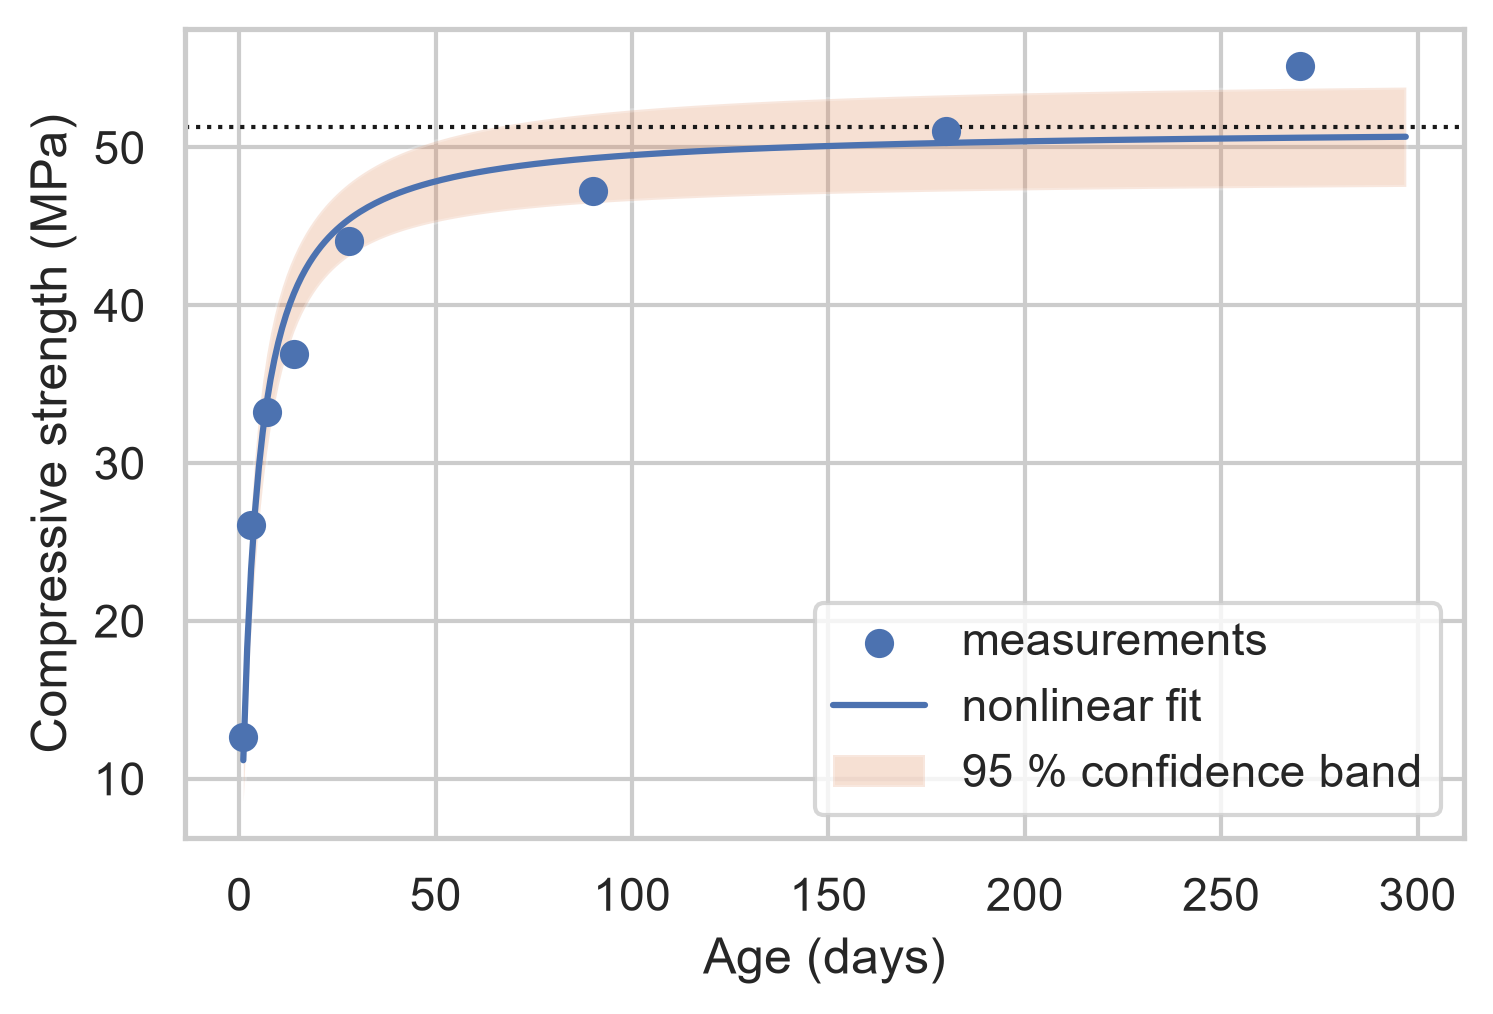

In [9]:
#| code-fold: false
# 95 % confidence band of the fitted curve (delta method)
t = np.linspace(1, mix["age"].max() * 1.1, 300)
f_inf, a = popt
J = np.column_stack([t / (a + t), -f_inf * t / (a + t) ** 2])   # partial derivatives
se = np.sqrt(np.einsum("ij,jk,ik->i", J, pcov, J))
fit = strength_model(t, *popt)

plt.scatter(mix["age"], mix["strength"], label="measurements", zorder=3)
plt.plot(t, fit, label="nonlinear fit")
plt.fill_between(t, fit - 1.96 * se, fit + 1.96 * se, alpha=0.25, label="95 % confidence band")
plt.axhline(f_inf, ls=":", c="k", lw=1)
plt.xlabel("Age (days)"); plt.ylabel("Compressive strength (MPa)"); plt.legend()
plt.show()

**Discussion.** The two parameters have a direct engineering meaning and can be compared between mixes. The confidence band is computed with the **delta method**: the variance of the fitted curve is approximated by $J\,\text{Cov}(\hat\theta)\,J^\top$, where $J$ contains the partial derivatives of the model with respect to the parameters. The band is narrow where many measurements exist and widens towards long ages. A strong correlation between $\hat f_\infty$ and $\hat a$ is typical for saturation models: if the data do not reach the plateau, a higher final strength reached later explains them almost equally well.

## Back to the decision

A strength promise concerns *individual* elements, not the average of many – so the relevant interval is the **prediction interval**. To be on the safe side, we require that the lower end of the 95 % prediction interval reaches 35 MPa. We check 28 days and, if necessary, search for the earliest age at which the requirement is met.

In [10]:
#| code-fold: false
required = 35.0
ages = np.arange(1, 366)
candidates = pd.concat([new_mix.drop(columns="age")] * len(ages), ignore_index=True).assign(age=ages)
pi_low = model.get_prediction(candidates).summary_frame(alpha=0.05)["obs_ci_lower"].values
low_28 = pi_low[ages == 28][0]
print(f"Lower 95 % prediction bound at 28 days: {low_28:.1f} MPa")
if low_28 >= required:
    print("Decision: approve the mix for the 28-day promise.")
elif (pi_low >= required).any():
    print(f"Decision: not at 28 days – promise {ages[np.argmax(pi_low >= required)]} days, or confirm with test specimens.")
else:
    print("Decision: the model cannot guarantee 35 MPa within a year – adjust the mix (e.g. lower w/c ratio).")

Lower 95 % prediction bound at 28 days: 19.9 MPa
Decision: not at 28 days – promise 158 days, or confirm with test specimens.


The recommendation should also state the limits of the model: it is a linear approximation fitted to laboratory specimens from one study, and the residual analysis showed systematic deviations. In practice, no plant would release a new mix on the basis of a regression model alone – but the model tells us whether the trial batches are worth casting and which test age to plan.

## Extension: design of experiments – a 2³ full factorial design

*Extension – optional material, not required for the exam.*

The concrete data are *observational*: the mixes were not chosen to estimate effects efficiently, and the inputs are correlated. In a **designed experiment** we choose the factor settings ourselves, so that the effects can be separated cleanly with as few runs as possible.

::: {.callout-note}
## Definition: Full factorial design
In a $2^k$ full factorial design, each of $k$ factors is set to a low (−1) and a high (+1) level, and all $2^k$ combinations are run. The columns of the coded design matrix are **orthogonal**, so all main effects and interactions are estimated independently of each other and with the smallest possible variance.
:::

With three factors, 8 runs estimate 3 main effects, 3 two-factor interactions and 1 three-factor interaction. **Replicates** (repeating all runs) provide an estimate of the experimental error. **Randomising** the run order protects against drifts in the test setup.

The example simulates such an experiment with a known "true" model, so we can check whether the analysis recovers it.

In [11]:
#| code-fold: false
import itertools

design = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)),
                      columns=["cement", "water", "age"])
rng = np.random.default_rng(42)
design = pd.concat([design, design], ignore_index=True)        # 2 replicates
design["strength"] = (40 + 8 * design.cement - 6 * design.water + 5 * design.age
                      + 2 * design.cement * design.age + rng.normal(0, 1.5, len(design)))

doe = smf.ols("strength ~ cement * water * age", data=design).fit()
print(doe.params.round(2))
print("Correlation between design columns:\n",
      np.round(np.corrcoef(design[["cement", "water", "age"]].T.values), 2))

Intercept           39.92
cement               7.59
water               -5.40
cement:water        -0.33
age                  4.80
cement:age           2.19
water:age           -0.11
cement:water:age    -0.54
dtype: float64
Correlation between design columns:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


The estimated coefficients reproduce the true values (8, −6, 5 and 2 for the cement × age interaction) up to the noise, and the non-existing interactions are estimated near zero. With coded factors, a coefficient is half the **effect** (change of the response from the low to the high level). The design columns are uncorrelated – the exact opposite of the observational concrete data.

::: {.callout-important}
## Key takeaways
- Linear regression is linear in the parameters; transformations and interactions make it flexible.
- Coefficients mean "change per unit, all else constant" – collinearity makes this hard to interpret.
- Check residuals for patterns; R² alone does not validate a model.
- Use prediction intervals for single new observations; beware of extrapolation.
- Nonlinear models with physically meaningful parameters are fitted with `curve_fit`; good starting values and parameter correlations deserve attention.
:::

## Exercises

<div class="exercises">

1. Replace `np.log(age)` by `age` in the linear model. How do R² and the residual plot change? Explain physically why the log transform helps.
2. Compute the water/cement ratio and use it as an input instead of `water` and `cement`. Compare R² and interpretability with the original model.
3. Which coefficients of the concrete model are statistically significant? Are the signs plausible from a materials point of view? Relate your answer to the VIF values.
4. Fit the strength model $f_\infty\,t/(a+t)$ to all mixes with at least four test ages. How does the final strength $f_\infty$ depend on the water/cement ratio?
5. Compare the hyperbolic model with a logarithmic model $f(t) = c_0 + c_1 \ln t$ for the selected mix. Which one extrapolates more plausibly to 1000 days, and why is extrapolation risky anyway?
6. (Extension) Extend the DoE example to a $2^4$ design with a fourth factor. How many runs are needed? What is a fractional factorial design, and what is its price?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

R² with log(age): 0.819,  with age: 0.616


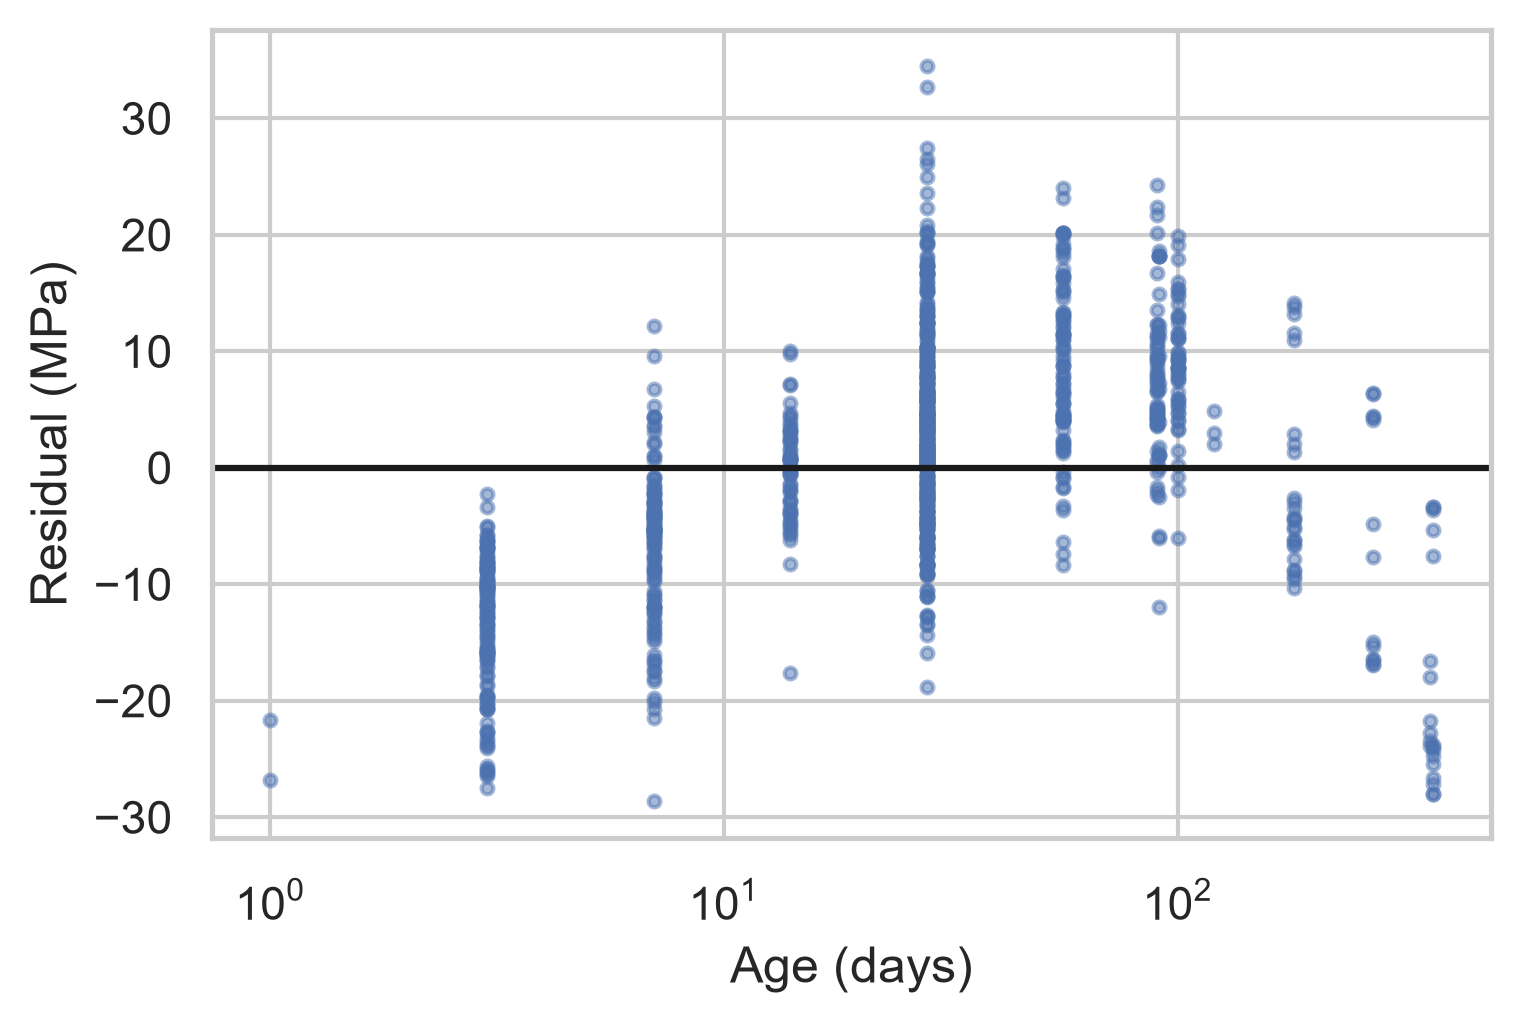

In [12]:
#| code-fold: false
model_lin_age = smf.ols("strength ~ cement + slag + fly_ash + water + superplasticizer"
                        " + coarse_agg + fine_agg + age", data=conc).fit()
print(f"R² with log(age): {model.rsquared:.3f},  with age: {model_lin_age.rsquared:.3f}")
plt.scatter(conc["age"], model_lin_age.resid, s=8, alpha=0.5)
plt.axhline(0, c="k"); plt.xscale("log"); plt.xlabel("Age (days)"); plt.ylabel("Residual (MPa)")
plt.show()

With a linear age term, R² drops noticeably and the residuals show a clear curved pattern over age: the model overestimates young and very old specimens and underestimates intermediate ages. Physically, hydration of cement is fast in the first days and slows down later – the strength gain per day decreases with age. $\ln(\text{age})$ captures this diminishing return.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

In [13]:
#| code-fold: false
conc["wc"] = conc["water"] / conc["cement"]
model_wc = smf.ols("strength ~ wc + slag + fly_ash + superplasticizer"
                   " + coarse_agg + fine_agg + np.log(age)", data=conc).fit()
print(f"R²: original {model.rsquared:.3f}, with w/c ratio {model_wc.rsquared:.3f}")
model_wc.params.round(3)

R²: original 0.819, with w/c ratio 0.759


Intercept           21.087
wc                 -35.379
slag                 0.083
fly_ash              0.036
superplasticizer     0.475
coarse_agg           0.001
fine_agg             0.003
np.log(age)          8.240
dtype: float64

The fit is of similar quality – the w/c ratio carries most of the information of water and cement together. The advantage is interpretability: the coefficient of `wc` directly expresses the well-known strength loss with increasing water/cement ratio, a quantity concrete engineers think in. Strictly, Abrams' law is nonlinear (strength ∝ $B^{-w/c}$ with a material constant $B$), so $\ln(\text{strength})$ vs. `wc` might fit even better.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [14]:
#| code-fold: false
pd.DataFrame({"coef": model.params, "p": model.pvalues, "VIF": vif}).round(4)

,coef,p,VIF
Intercept,-77.5334,0.0000,NaN
cement,0.1349,0.0000,7.5324
coarse_agg,0.0297,0.0000,5.0890
fine_agg,0.0360,0.0000,7.0304
fly_ash,0.0944,0.0000,6.1411
log_age,NaN,NaN,1.0523
np.log(age),8.7466,0.0000,NaN
slag,0.1159,0.0000,7.2792
superplasticizer,0.1188,0.0652,2.9803
water,-0.1288,0.0000,6.9839


Expected signs: cement, slag and fly ash (binders) and superplasticizer positive; water negative; age positive. Coefficients that are not significant or have counterintuitive signs typically belong to inputs with high VIF – the aggregates, which are strongly linked to the other components through the fixed total volume. Their individual coefficients cannot be interpreted reliably, even though the model as a whole predicts reasonably.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

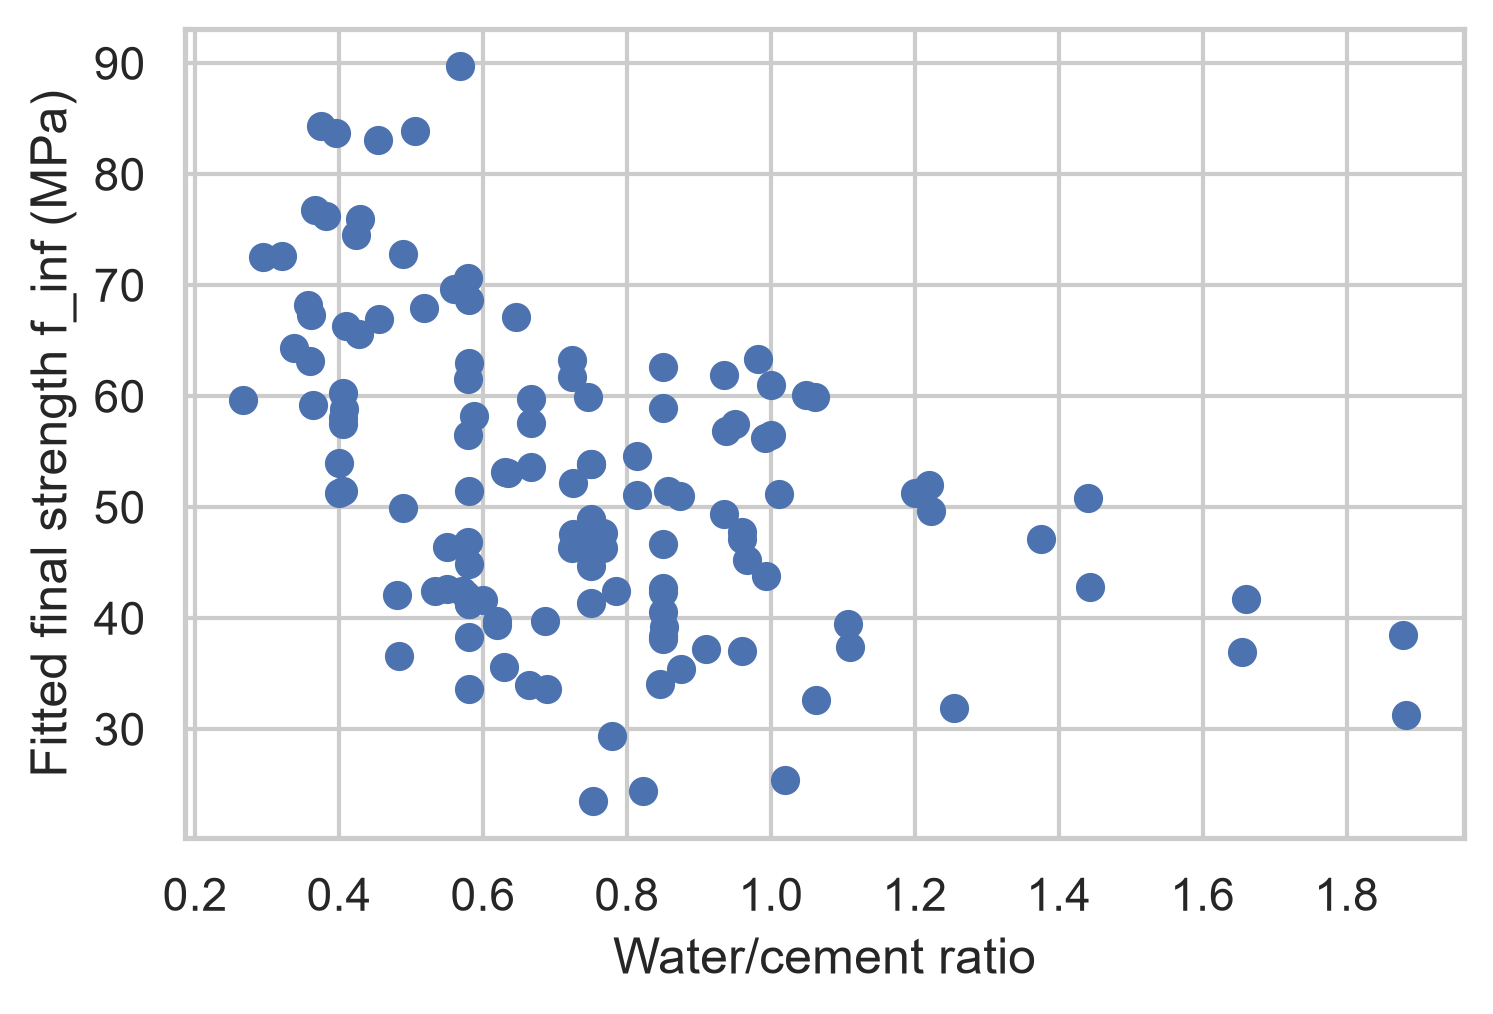

131 mixes fitted


In [15]:
#| code-fold: false
rows = []
for key, g in conc.groupby(mix_cols):
    if g["age"].nunique() < 4:
        continue
    try:
        p, _ = curve_fit(strength_model, g["age"], g["strength"],
                         p0=[g["strength"].max(), 7], maxfev=5000)
    except RuntimeError:
        continue                                          # fit did not converge
    rows.append({"wc": g["water"].iloc[0] / g["cement"].iloc[0], "f_inf": p[0], "a": p[1]})
fits = pd.DataFrame(rows)
fits = fits[(fits["a"] > 0) & (fits["f_inf"] < 200)]        # drop physically meaningless fits
plt.scatter(fits["wc"], fits["f_inf"])
plt.xlabel("Water/cement ratio"); plt.ylabel("Fitted final strength f_inf (MPa)")
plt.show()
print(f"{len(fits)} mixes fitted")

The final strength decreases clearly with increasing water/cement ratio – the same relationship as in the linear model, but now expressed through a physically meaningful parameter. Some fits must be discarded because the mix was tested at too few or too early ages to determine the plateau (the parameters are then not identifiable). Checking plausibility of fitted parameters is an essential step when fitting many curves automatically.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5

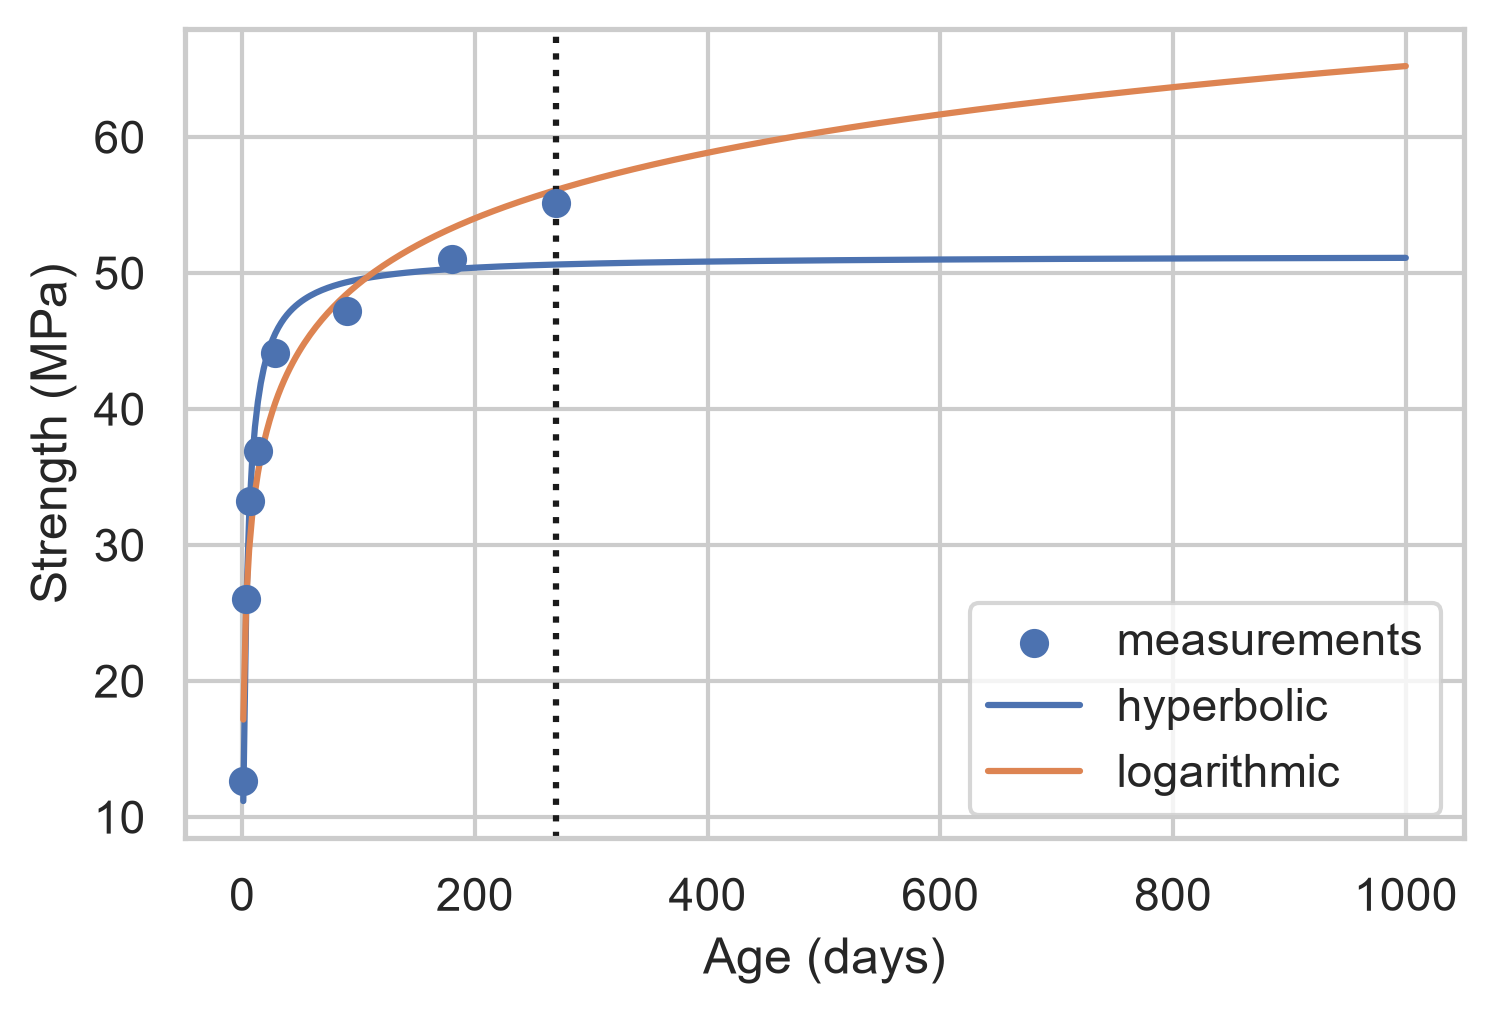

In [16]:
#| code-fold: false
c1, c0 = np.polyfit(np.log(mix["age"]), mix["strength"], deg=1)
t_long = np.linspace(1, 1000, 400)
plt.scatter(mix["age"], mix["strength"], zorder=3, label="measurements")
plt.plot(t_long, strength_model(t_long, *popt), label="hyperbolic")
plt.plot(t_long, c0 + c1 * np.log(t_long), label="logarithmic")
plt.axvline(mix["age"].max(), ls=":", c="k")
plt.xlabel("Age (days)"); plt.ylabel("Strength (MPa)"); plt.legend()
plt.show()

Within the measured range both models can fit similarly well. Beyond it, the logarithmic model grows without bound, while the hyperbolic model approaches a final strength – physically more plausible, since hydration eventually stops. But neither model is validated beyond the last measurement: long-term effects (e.g. carbonation, drying) are not in the data. Extrapolation relies on the model *form*, not on data – and different plausible forms can give very different answers.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 6
A $2^4$ full factorial design needs $2^4 = 16$ runs (32 with two replicates). It estimates 4 main effects, 6 two-factor, 4 three-factor and 1 four-factor interaction. A **fractional factorial design** $2^{4-1}$ uses only 8 runs, chosen such that the main effects remain orthogonal. The price is **aliasing**: some effects can no longer be distinguished – in the $2^{4-1}$ design with generator $D = ABC$, each main effect is aliased with a three-factor interaction and the two-factor interactions are aliased in pairs. This is acceptable when higher-order interactions are negligible, which is often the case in screening experiments.

In [17]:
#| code-fold: false
design4 = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=list("ABC"))
design4["D"] = design4["A"] * design4["B"] * design4["C"]       # generator D = ABC
design4

,A,B,C,D
0,-1,-1,-1,-1
1,-1,-1,1,1
2,-1,1,-1,1
3,-1,1,1,-1
4,1,-1,-1,1
5,1,-1,1,-1
6,1,1,-1,-1
7,1,1,1,1


:::